# Viewing detected audio segments (unaligned)

In [6]:
import cPickle as pickle
import os

import numpy as np
import matplotlib.pyplot as plt
import quantities as pq
import scipy.sparse as sparse
from IPython.display import Audio, display

import soundsig
from soundsig.sound import spectrogram, plot_spectrogram

import config

from spikes.plotting import plot_spikes_with_timeseries
from spikes.plotting.segment_view import PlaybacksManager, SegmentViewer, TrialsViewer
from spikes.sorting.preprocess import collect_waveforms
from spikes.utils import bin_spikes

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [7]:
BIRD_NAME = "LbY6074"
BIRD = "LbY6074__161215_145633"

In [8]:
DATADIR = config.DATADIR
data_path = os.path.join(DATADIR, "birds", BIRD_NAME, BIRD, "spikes", "{}-sorted.pkl".format(BIRD))

In [9]:
with open(data_path, "rb") as datafile:
    block = pickle.load(datafile)
block.create_relationship(recursive=True, force=True, append=True)

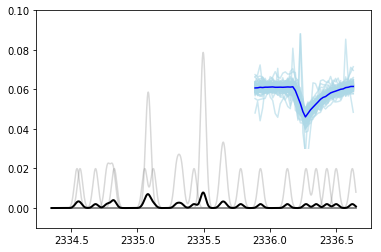

In [17]:
plt.figure(figsize=(6, 4))
trials_viewer.plot_psth(0)
plt.ylim(-.01, 0.1)

plt.axes([.62, .4, .25, .4])
wfs = trials_viewer.waveforms(unit=4)[0]
plt.plot(wfs.T, color="lightblue", alpha=0.6)
plt.plot(np.mean(wfs, axis=0), color="blue")
plt.ylim(-400, 400)
plt.axis("off")
plt.show()


## By segment

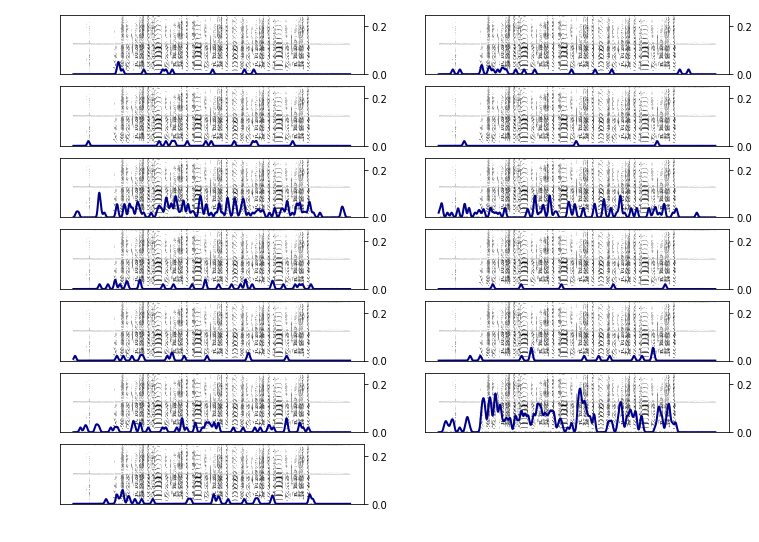

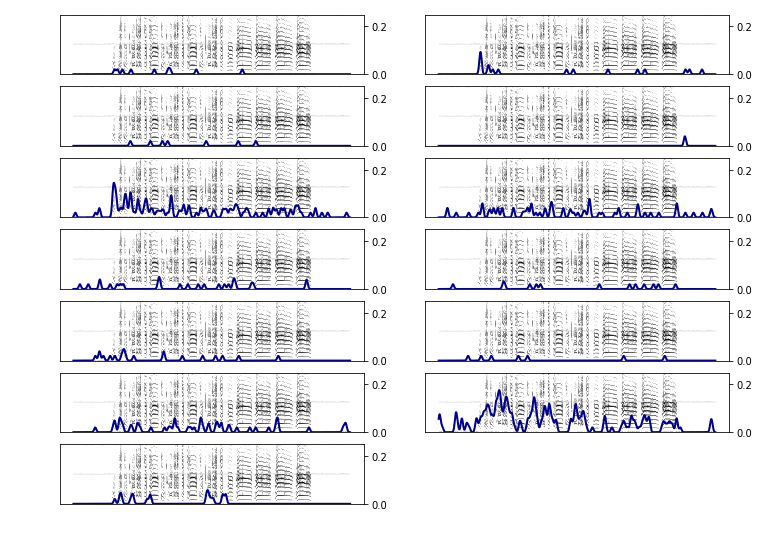

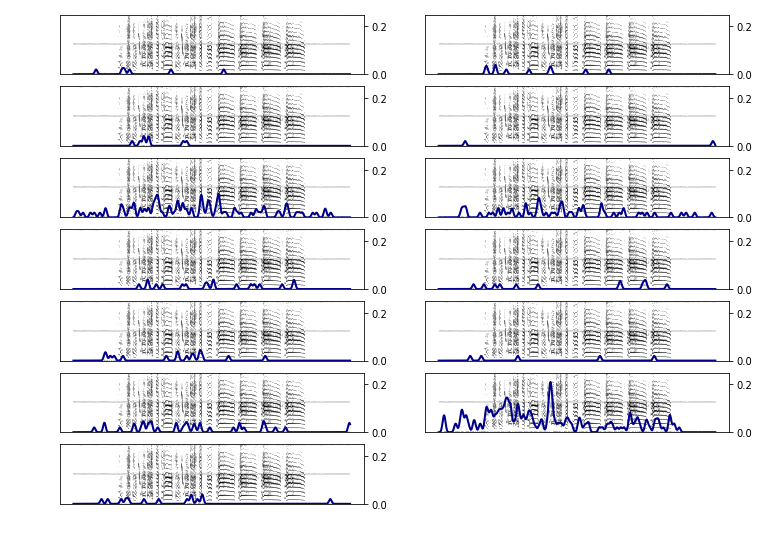

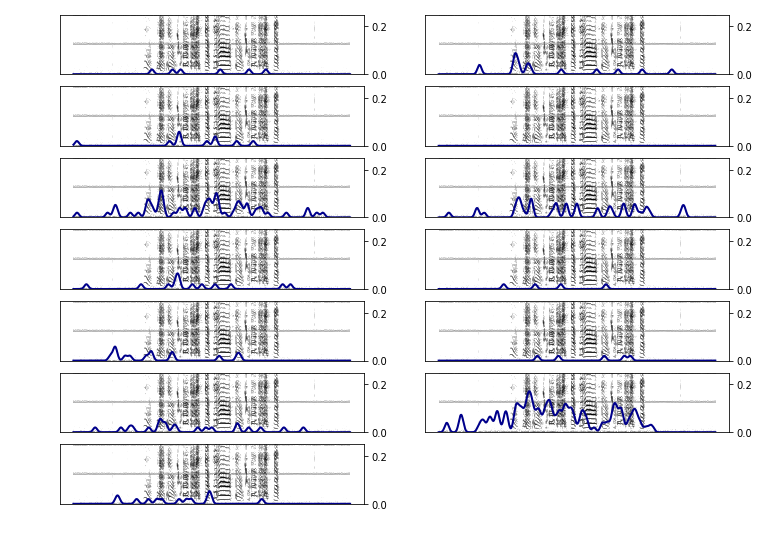

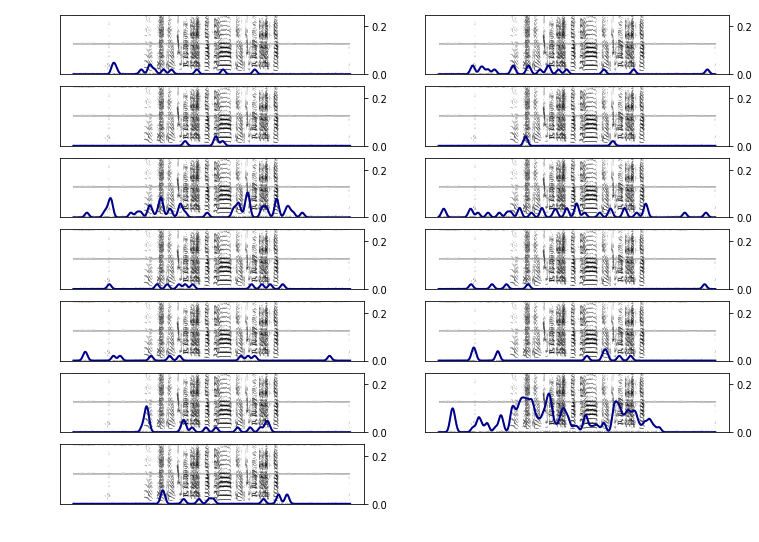

...

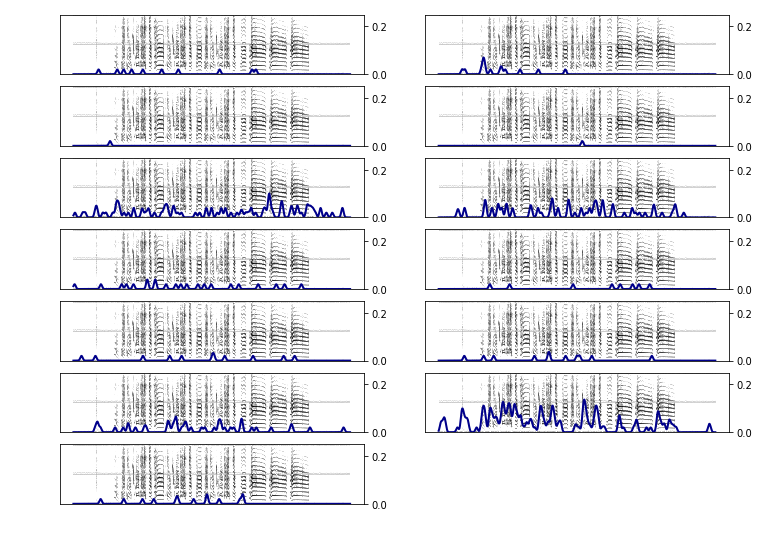

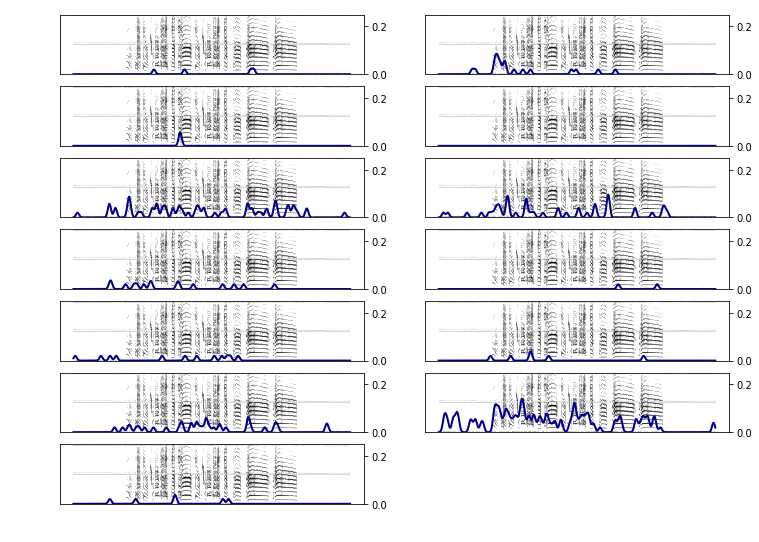

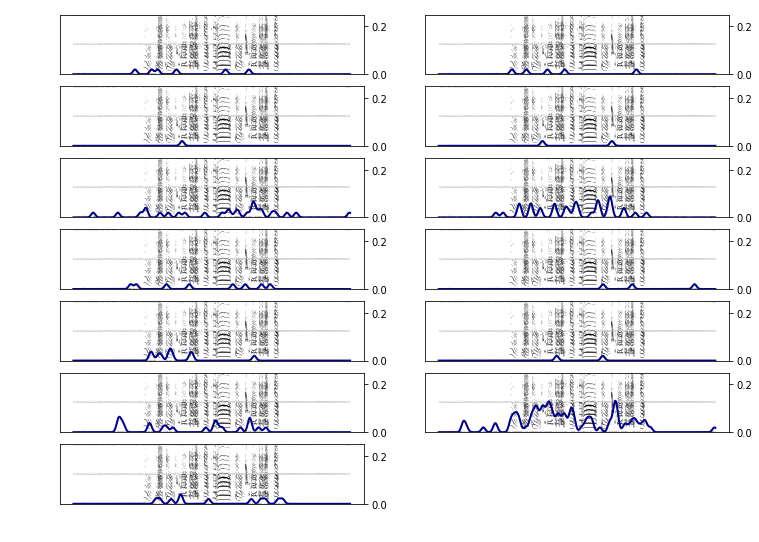

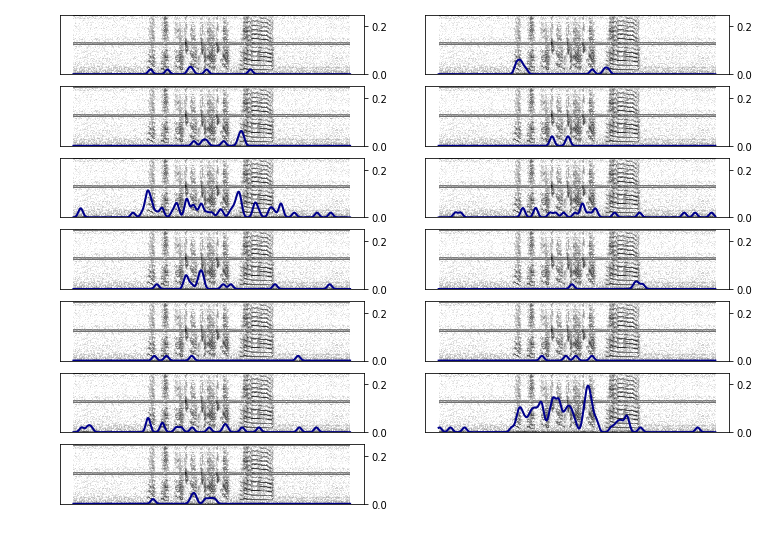

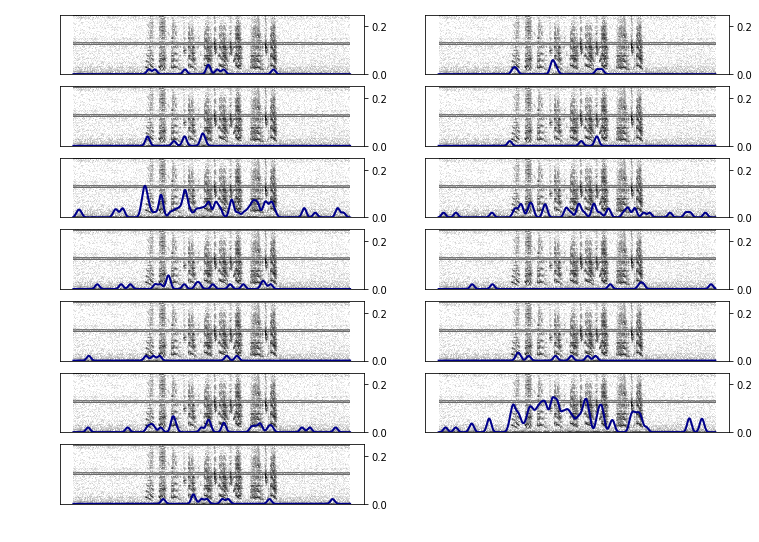

In [59]:
plt.clf()
for seg in block.segments[:16]:
    if seg.annotations["sound_type"] == "playback":
        continue
    seg_viewer = SegmentViewer(seg)
    trials_viewer = TrialsViewer([seg])
    
#     # TODO: view spectrogram of playback wav file too
#     fig, ax = plt.subplots(figsize=(8, 3))
#     seg_viewer.plot_spectrogram(source=0, ax=ax)
#     ax.set_xlim(0, 6.0)
#     plt.show()

    plt.figure(figsize=(12, 9))
    for unit in trials_viewer.units:
        ax = plt.subplot(7, 2, unit + 1)
        seg_viewer.plot_spectrogram(source=0, ax=ax, t_start=trials_viewer.t_arr()[0])
        plt.axis("off")
        ax = ax.twinx()
        trials_viewer.plot_psth(unit, ax=ax, color="DarkBlue")
        ax.set_ylim(0, 0.25)

    #plt.tight_layout()
    plt.show()

## By units

Unit 0


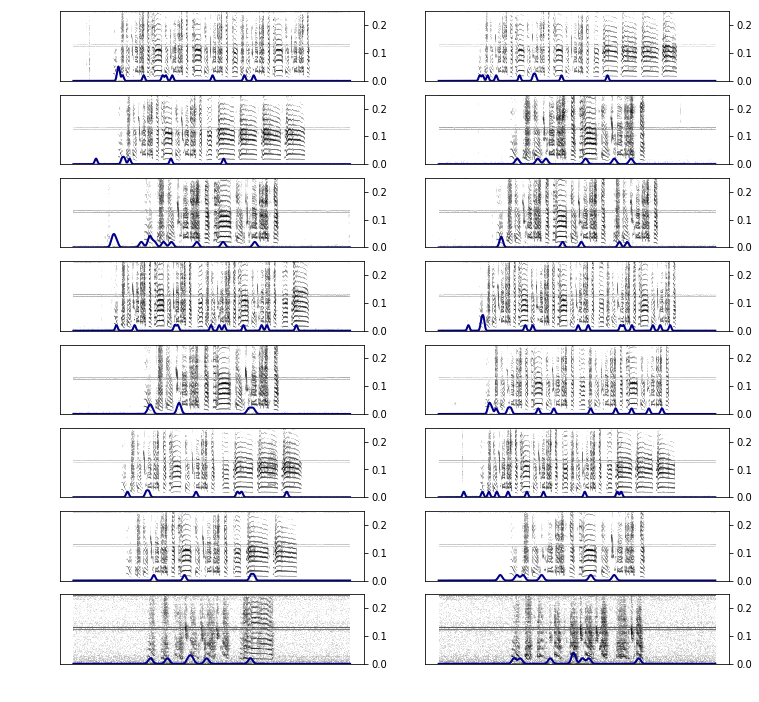

Unit 1


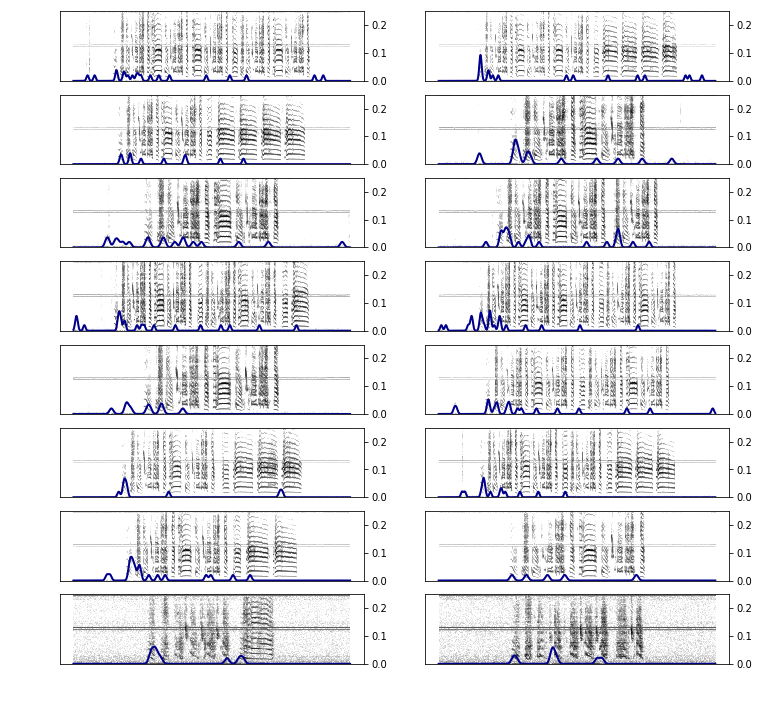

Unit 2


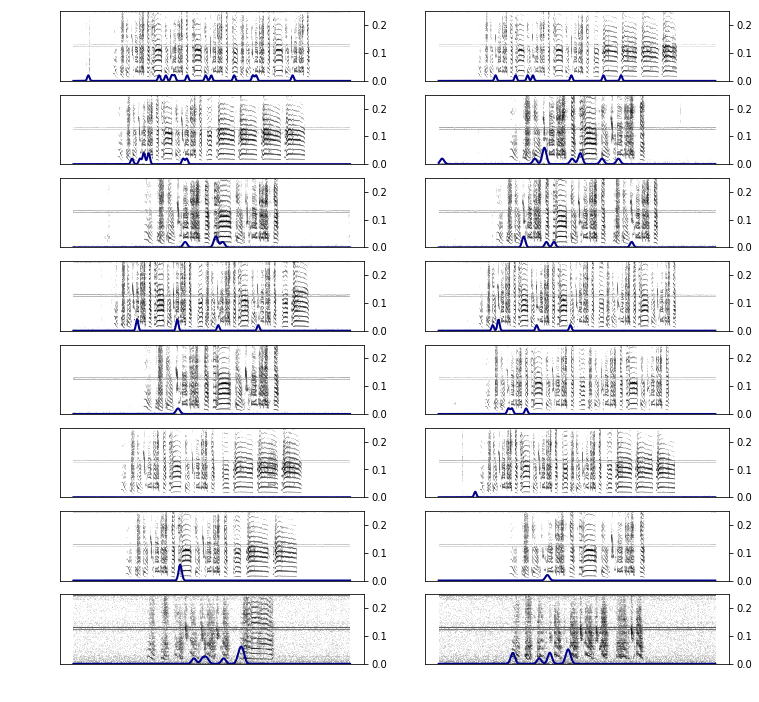

Unit 3


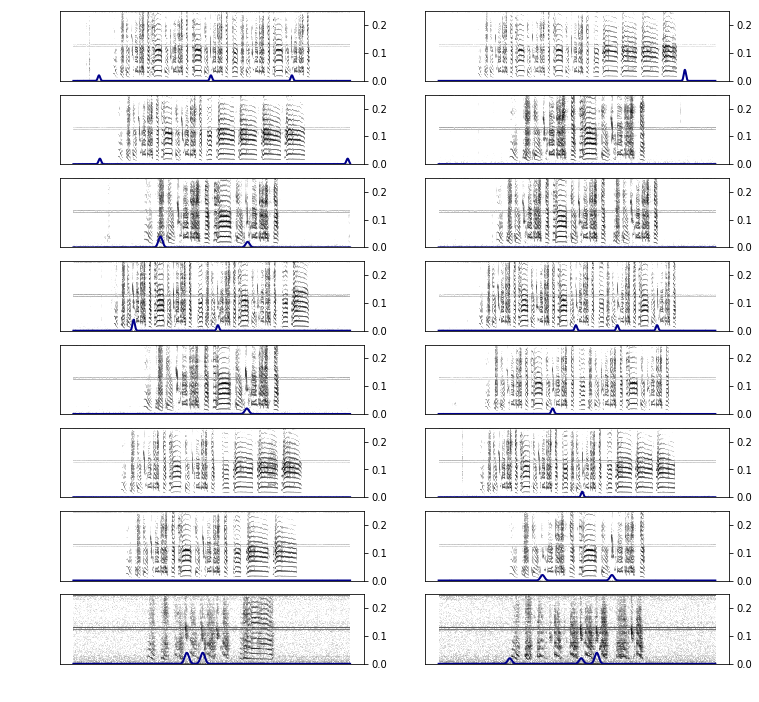

Unit 4


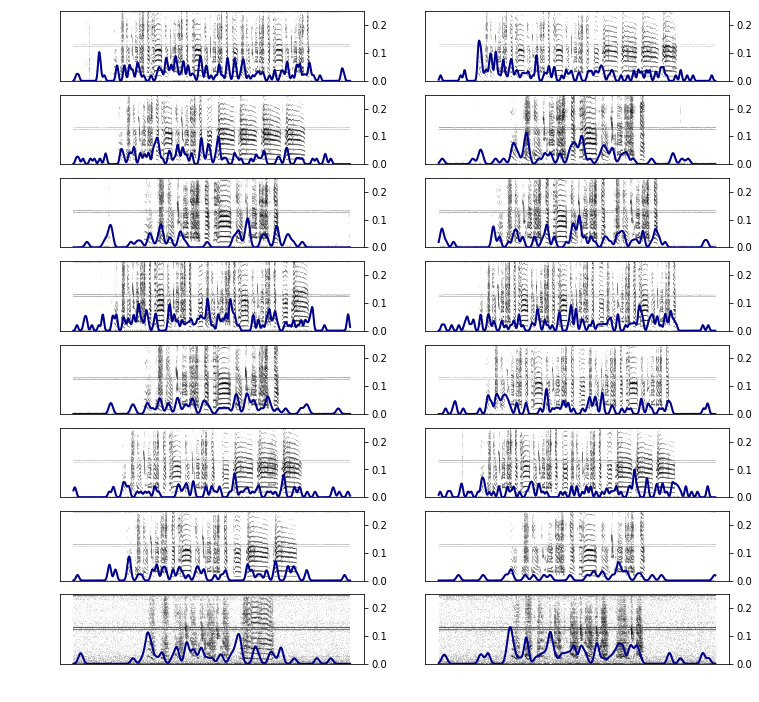

Unit 5


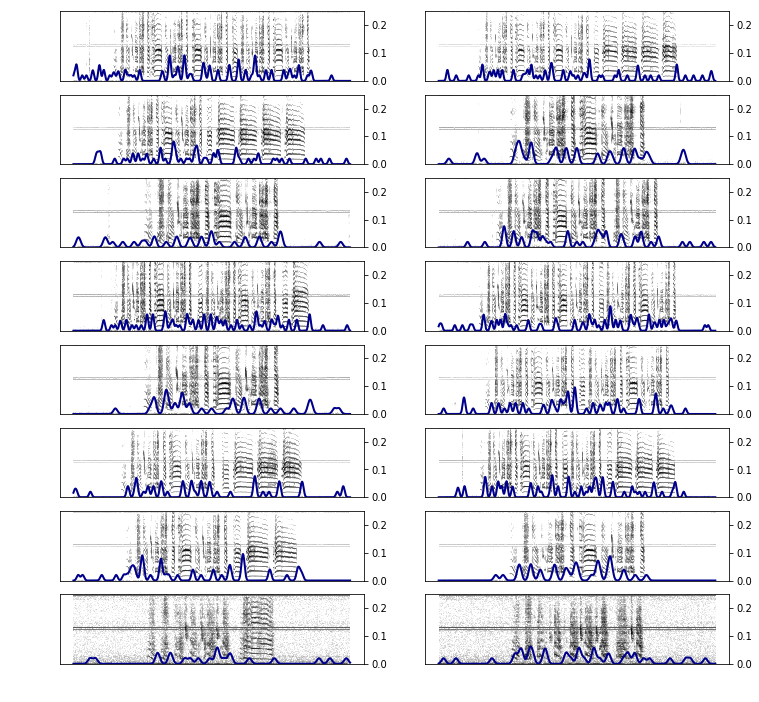

Unit 6


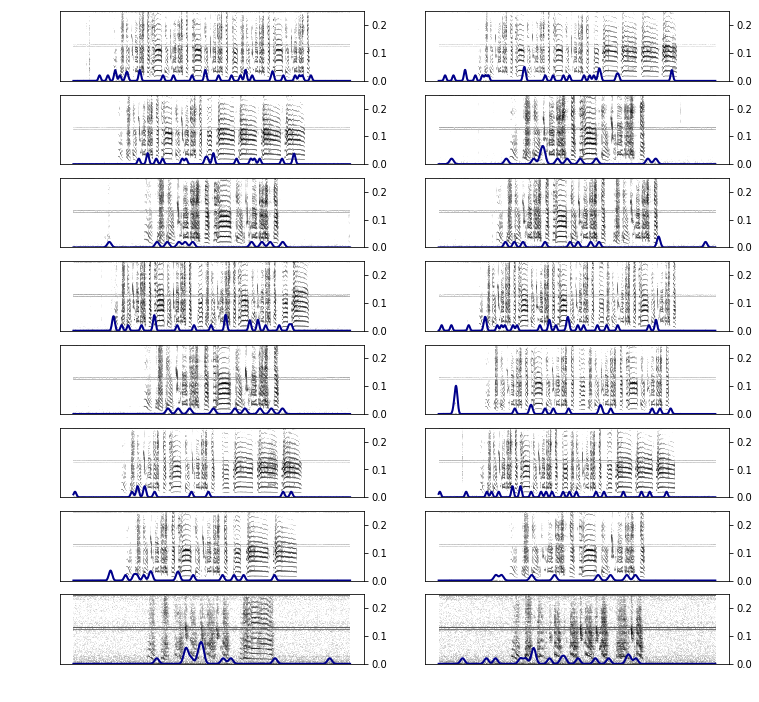

Unit 7


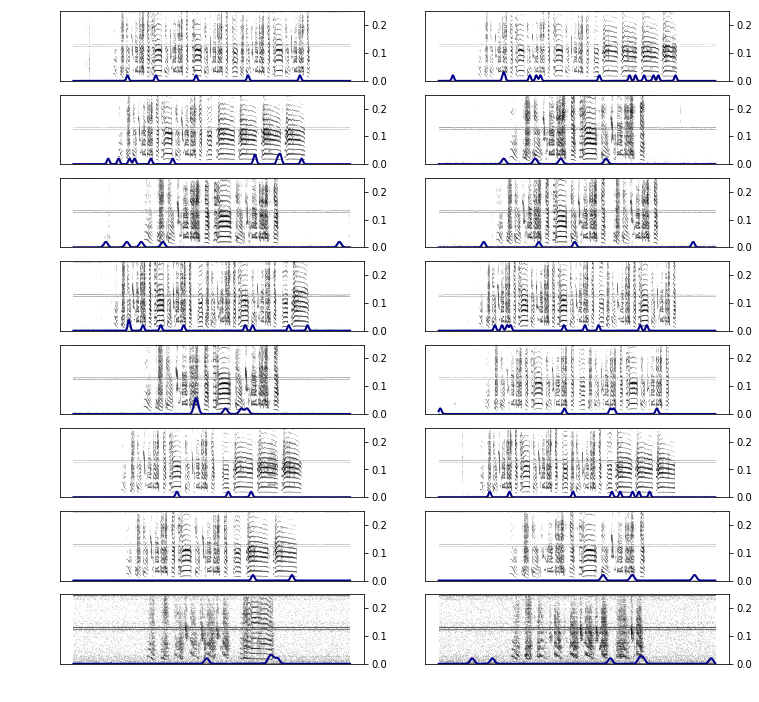

Unit 8


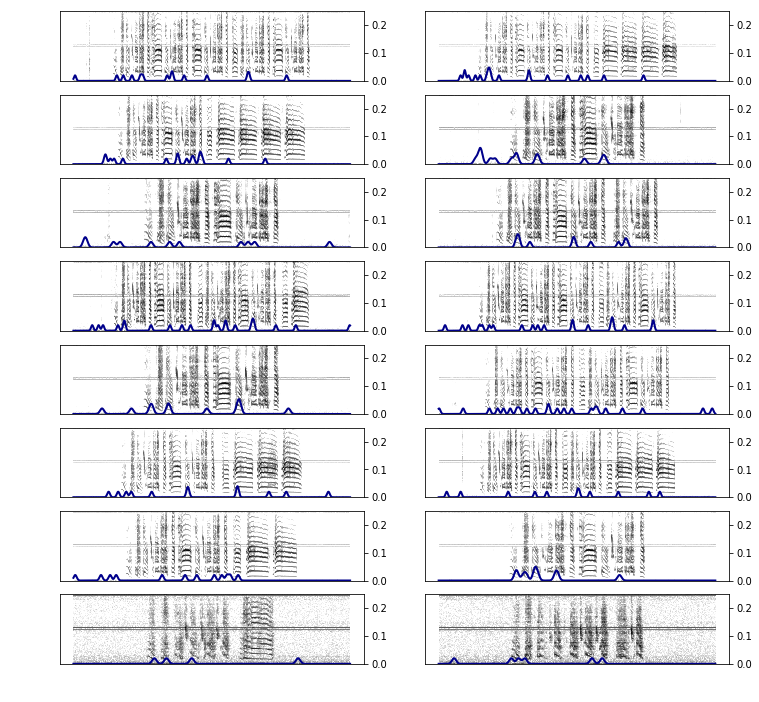

Unit 9


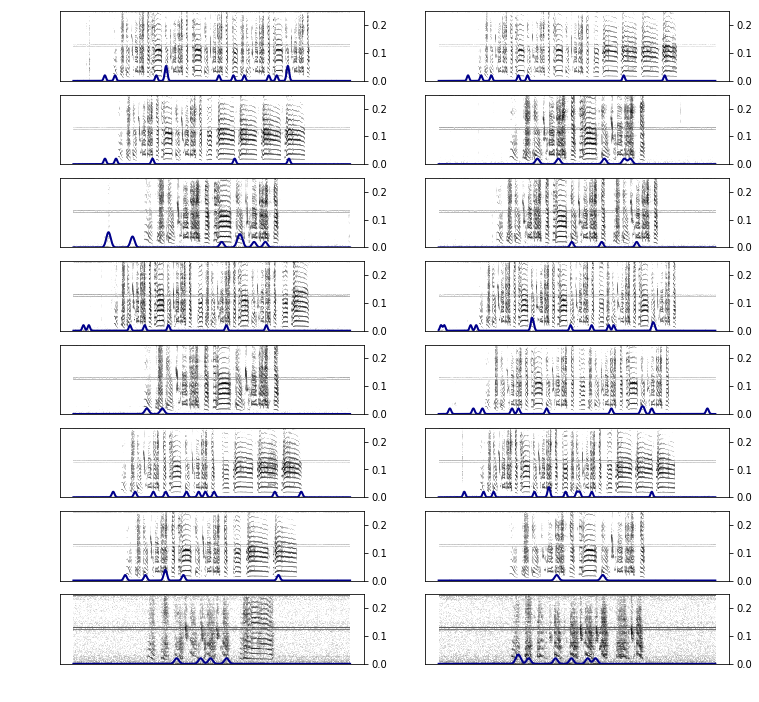

Unit 10


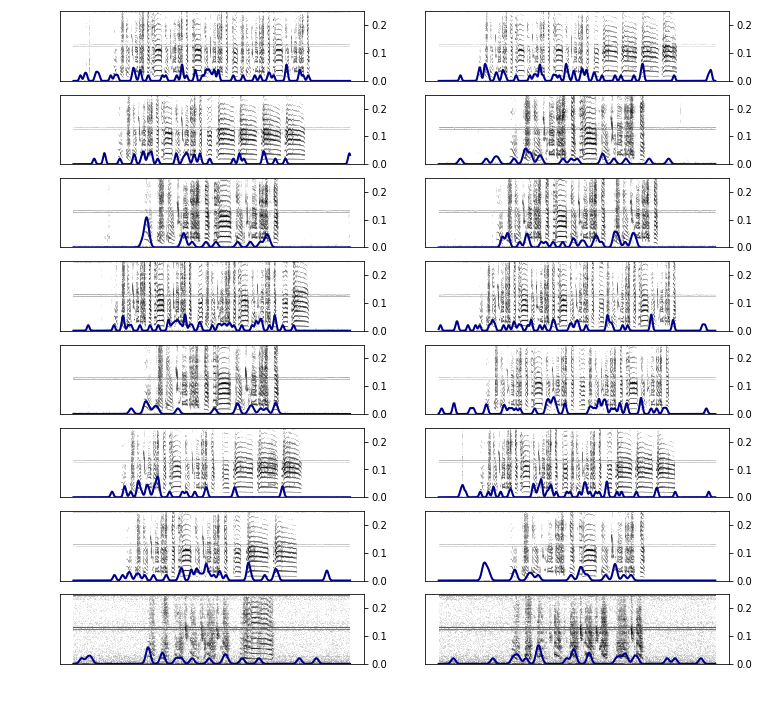

Unit 11


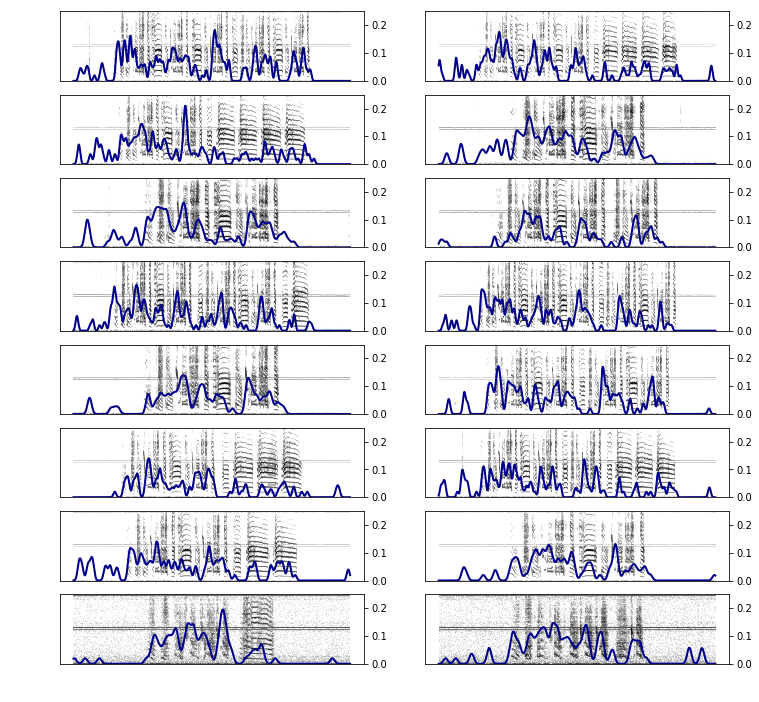

Unit 12


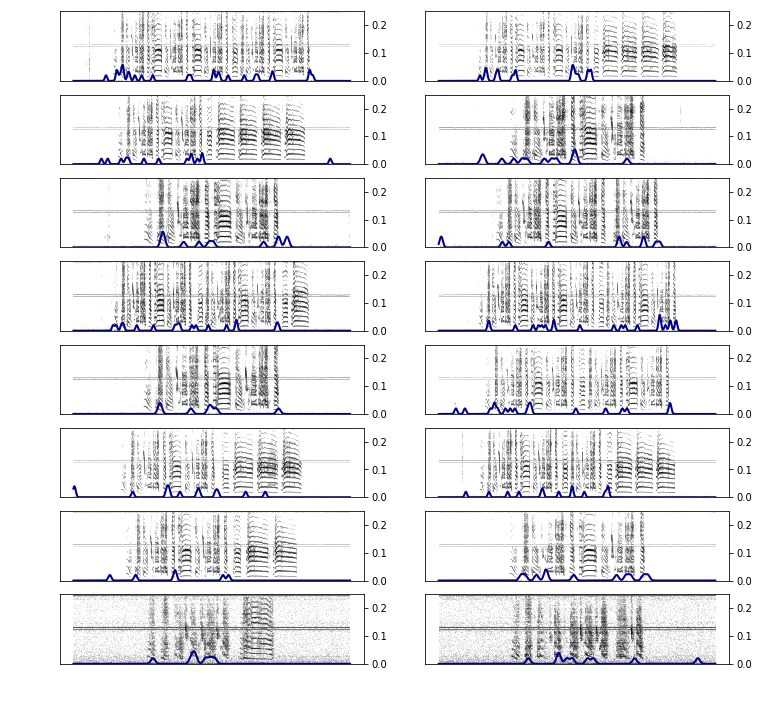

In [56]:
plt.clf()
seg_viewers = [SegmentViewer(seg) for seg in block.segments]
trials_viewers = [TrialsViewer([seg]) for seg in block.segments]

for unit in range(len(block.segments[0].spiketrains)):
    print "Unit {}".format(unit)
    
    if seg.annotations["sound_type"] == "playback":
        continue

    plt.figure(figsize=(12, 12))
    for i, seg in enumerate(block.segments[:16]):
        seg_viewer = seg_viewers[i]
        trials_viewer = trials_viewers[i]

        ax = plt.subplot(8, 2, i + 1)
        seg_viewer.plot_spectrogram(source=0, ax=ax, t_start=trials_viewer.t_arr()[0])
        plt.axis("off")
        ax = ax.twinx()
        trials_viewer.plot_psth(unit, ax=ax, color="DarkBlue")
        ax.set_ylim(0, 0.25)

    #plt.tight_layout()
    plt.show()

In [50]:
len(block.segments)

100

## View all segments

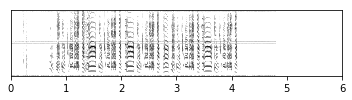

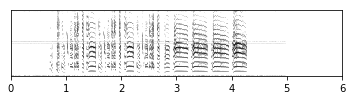

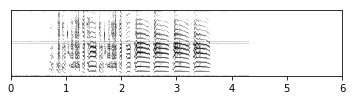

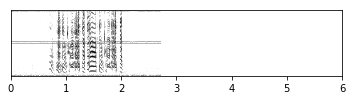

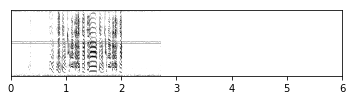

...

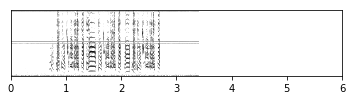

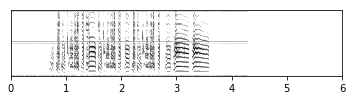

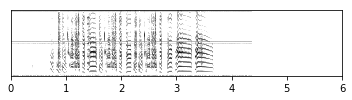

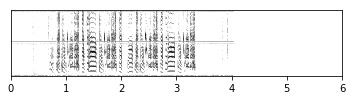

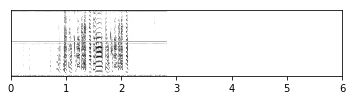

In [72]:
plt.clf()
for i, seg in enumerate(block.segments[:]):
    if seg.annotations["sound_type"] == "playback":
        continue
    seg_viewer = SegmentViewer(seg)
    trials_viewer = TrialsViewer([seg])
    
    # TODO: view spectrogram of playback wav file too
    plt.figure(figsize=(5, 1.5))
    seg_viewer.plot_spectrogram(source=0)
    plt.xlim(0, 6.0)
    plt.ylabel("")
    plt.xlabel("")
    plt.yticks([])

    plt.tight_layout()
    plt.show()

In [73]:
align4 = [0, 7, 16, 80]
align3 = [1, 9, 11, 19, 21, 68, 69, 71, 73, 74, 82, 95, 97, 97, 98]
align2 = [2, 3, 4, 5, 8, 10, 12, 13, 17, 18, 20, 22, 67, 72, 85, 92, 93, 94, 99]

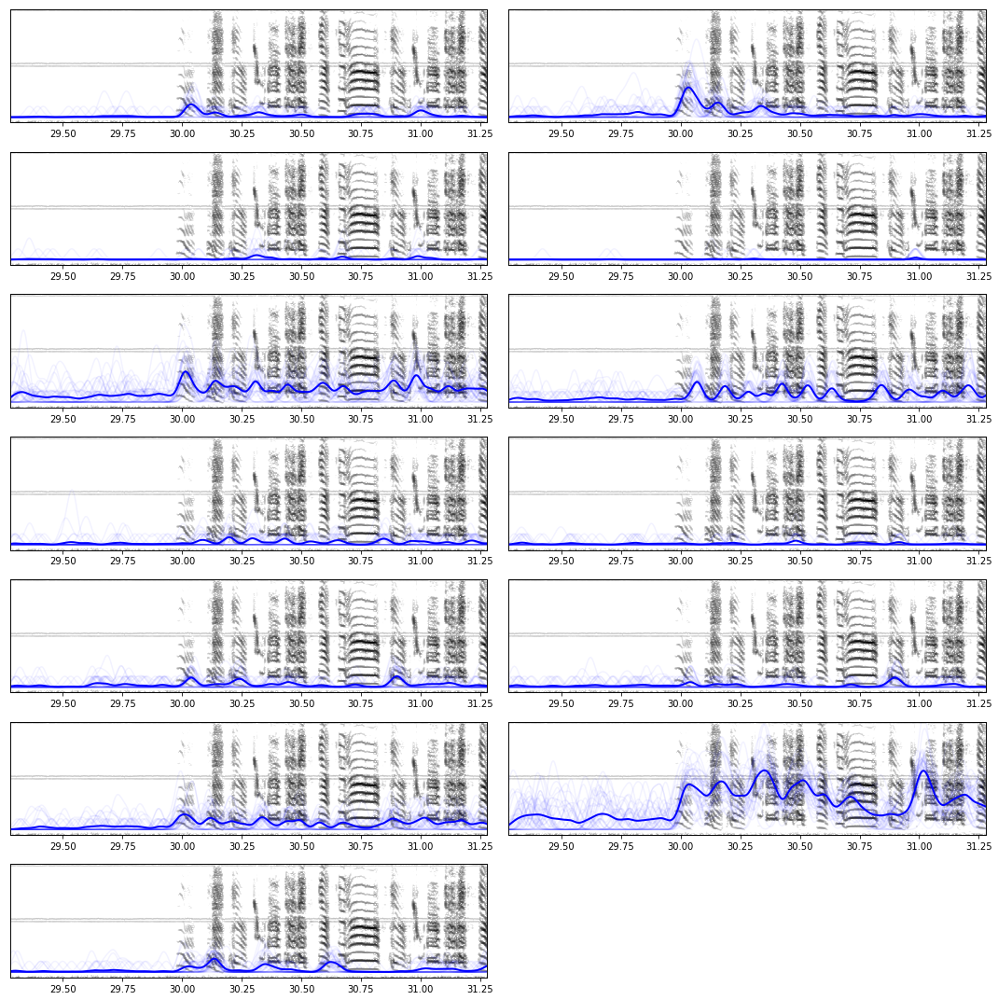

In [116]:
plt.clf()
trials_viewer = TrialsViewer(np.array(block.segments)[align2 + align3 + align4])
seg_viewer = trials_viewer.segment_viewers[0]

# TODO: view spectrogram of playback wav file too
# fig, ax = plt.subplots(figsize=(4, 3))
# seg_viewer.plot_spectrogram(ax=ax, source=0)
# ax.set_xlim(0, 2.0)
# plt.show()

plt.figure(figsize=(15, 15))
for unit in trials_viewer.units:
    ax = plt.subplot(7, 2, unit + 1)
    seg_viewer.plot_spectrogram(ax=ax, source=0, t_start=trials_viewer.t_arr()[0])
    plt.ylabel("")
    plt.xlabel("")
    plt.yticks([])

    ax = ax.twinx()
    trials_viewer.plot_psth(unit, ax=ax, color="Blue")
    plt.yticks([])
    
    plt.xlim(trials_viewer.t_arr()[0], trials_viewer.t_arr()[0] + 2.0)
    plt.ylim(-.01, 0.2)

plt.tight_layout()
plt.show()

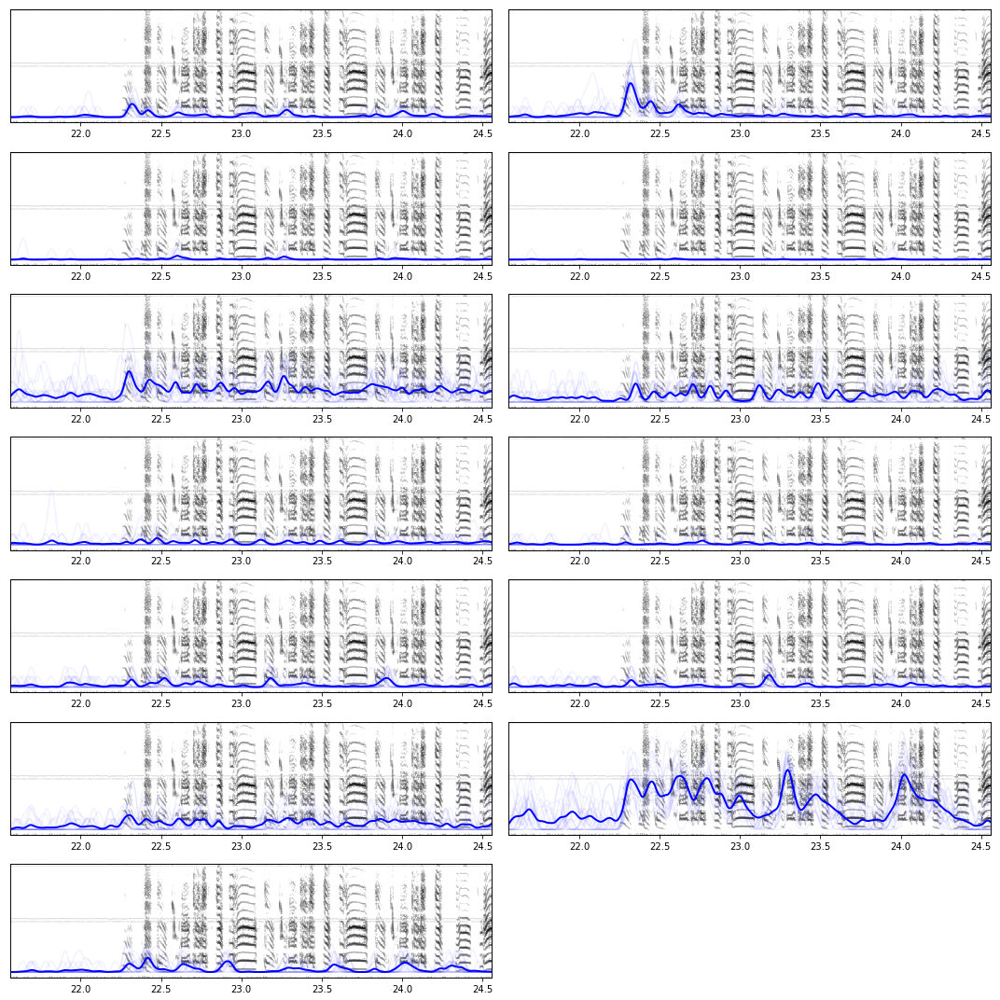

In [113]:
plt.clf()
trials_viewer = TrialsViewer(np.array(block.segments)[align3 + align4])
seg_viewer = trials_viewer.segment_viewers[0]

# TODO: view spectrogram of playback wav file too
# fig, ax = plt.subplots(figsize=(4, 3))
# seg_viewer.plot_spectrogram(ax=ax, source=0)
# ax.set_xlim(0, 3.0)
# plt.show()

plt.figure(figsize=(15, 15))
for unit in trials_viewer.units:
    ax = plt.subplot(7, 2, unit + 1)
    seg_viewer.plot_spectrogram(ax=ax, source=0, t_start=trials_viewer.t_arr()[0])
    plt.ylabel("")
    plt.xlabel("")
    plt.yticks([])

    ax = ax.twinx()
    trials_viewer.plot_psth(unit, ax=ax, color="Blue")
    plt.yticks([])

    plt.xlim(trials_viewer.t_arr()[0], trials_viewer.t_arr()[0] + 3.0)
    plt.ylim(-.01, 0.2)

plt.tight_layout()
plt.show()

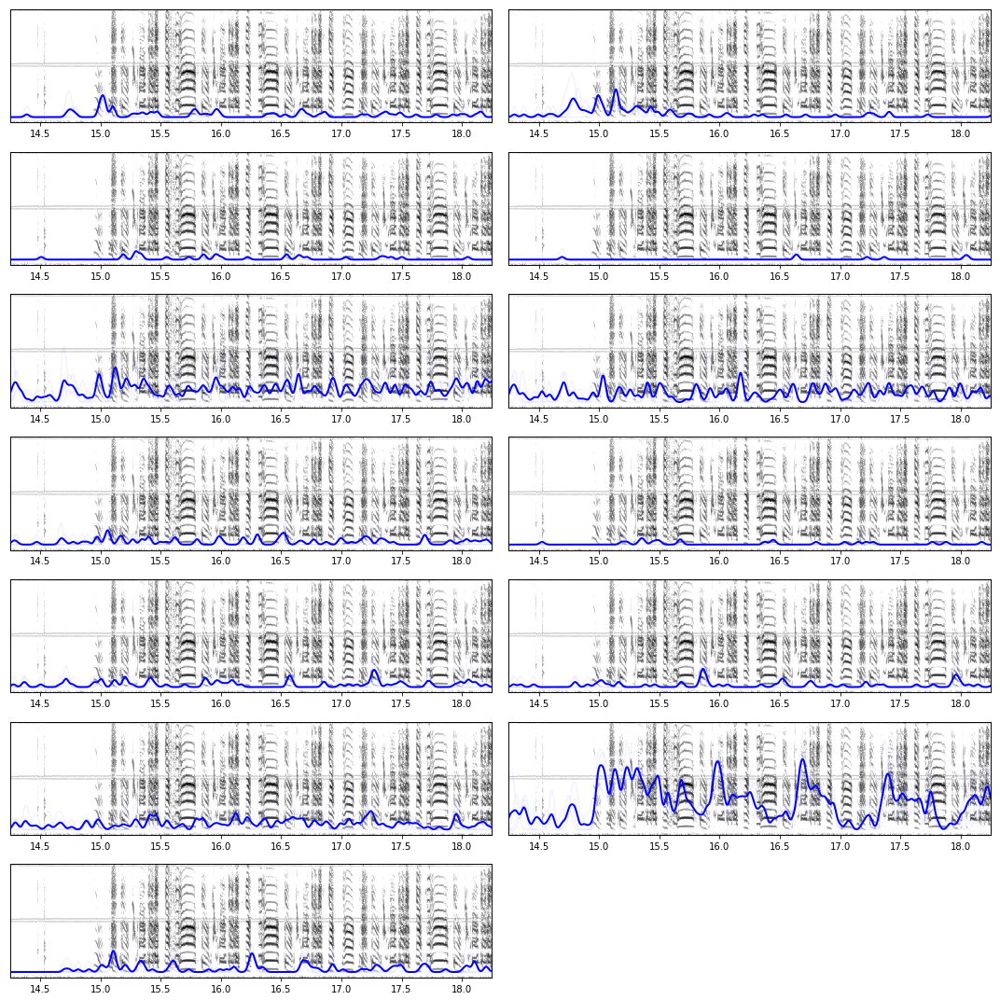

In [114]:
plt.clf()
trials_viewer = TrialsViewer(np.array(block.segments)[align4])
seg_viewer = trials_viewer.segment_viewers[0]

# TODO: view spectrogram of playback wav file too
# fig, ax = plt.subplots(figsize=(4, 3))
# seg_viewer.plot_spectrogram(ax=ax, source=0)
# ax.set_xlim(0, 4.0)
# plt.show()

plt.figure(figsize=(15, 15))
for unit in trials_viewer.units:
    ax = plt.subplot(7, 2, unit + 1)
    seg_viewer.plot_spectrogram(ax=ax, source=0, t_start=trials_viewer.t_arr()[0])
    plt.ylabel("")
    plt.xlabel("")
    plt.yticks([])

    ax = ax.twinx()
    trials_viewer.plot_psth(unit, ax=ax, color="Blue")
    plt.yticks([])

    plt.xlim(trials_viewer.t_arr()[0], trials_viewer.t_arr()[0] + 4.0)
    plt.ylim(-.01, 0.2)

plt.tight_layout()
plt.show()